In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt


In [2]:
df= pd.read_csv('Skyrun dataset.csv',  parse_dates=['InvoiceDate'])
print('Rows loaded:', len(df))
df['Revenue'] = df['Quantity'] * df['UnitPrice']
df.describe

Rows loaded: 541909


<bound method DataFrame.describe of        InvoiceNo         InvoiceDate  CustomerID StockCode  Description  \
0         536365 2024-12-01 08:26:00     17850.0    SC1734  Electronics   
1         536365 2024-12-01 08:26:00     17850.0    SC2088    Furniture   
2         536365 2024-12-01 08:26:00     17850.0    SC3463        Books   
3         536365 2024-12-01 08:26:00     17850.0    SC6228         Toys   
4         536365 2024-12-01 08:26:00     17850.0    SC2149         Toys   
...          ...                 ...         ...       ...          ...   
541904    581587 2025-12-09 12:50:00     12680.0    SC5440    Furniture   
541905    581587 2025-12-09 12:50:00     12680.0    SC3576       Cloths   
541906    581587 2025-12-09 12:50:00     12680.0    SC5283    Furniture   
541907    581587 2025-12-09 12:50:00     12680.0    SC1099    Cosmetics   
541908    581587 2025-12-09 12:50:00     12680.0    SC9276         Toys   

        Quantity  UnitPrice       Country  Revenue  
0         

In [3]:
df = df.dropna(subset=['CustomerID']).copy()
print('Rows left for analysis (no missing CustomerID):', len(df))

Rows left for analysis (no missing CustomerID): 406829


In [4]:
num_customer = df['CustomerID'].nunique()      
num_transaction = df['InvoiceNo'].nunique()    
num_products = df['StockCode'].nunique()       

In [5]:
df['InvoiceMonth'] = df['InvoiceDate'].dt.to_period('M')
df['Revenue'] = df['Quantity'] * df['UnitPrice']   

In [6]:
cohort_data = df.groupby('CustomerID')['InvoiceMonth'].min()

In [7]:
cohort_data.name = 'CohortMonth'
df = df.merge(cohort_data, on='CustomerID')

In [8]:
df.describe

<bound method DataFrame.describe of        InvoiceNo         InvoiceDate  CustomerID StockCode  Description  \
0         536365 2024-12-01 08:26:00     17850.0    SC1734  Electronics   
1         536365 2024-12-01 08:26:00     17850.0    SC2088    Furniture   
2         536365 2024-12-01 08:26:00     17850.0    SC3463        Books   
3         536365 2024-12-01 08:26:00     17850.0    SC6228         Toys   
4         536365 2024-12-01 08:26:00     17850.0    SC2149         Toys   
...          ...                 ...         ...       ...          ...   
406824    581587 2025-12-09 12:50:00     12680.0    SC5440    Furniture   
406825    581587 2025-12-09 12:50:00     12680.0    SC3576       Cloths   
406826    581587 2025-12-09 12:50:00     12680.0    SC5283    Furniture   
406827    581587 2025-12-09 12:50:00     12680.0    SC1099    Cosmetics   
406828    581587 2025-12-09 12:50:00     12680.0    SC9276         Toys   

        Quantity  UnitPrice       Country  Revenue InvoiceMonth

In [9]:
invoice_year, invoice_month = df['InvoiceMonth'].dt.year, df['InvoiceMonth'].dt.month
cohort_year, cohort_month = df['CohortMonth'].dt.year, df['CohortMonth'].dt.month
df['CohortIndex'] = (invoice_year - cohort_year) * 12 + (invoice_month - cohort_month) + 1

In [10]:
# CORRECTION 1: leave out December 2025 (only 9 days of data)
complete = df[df['InvoiceMonth'].astype(str) != '2025-12']

cohort_counts = complete.groupby(['CohortMonth', 'CohortIndex'])['CustomerID'].nunique().reset_index()

In [11]:
cohort_pivot = cohort_counts.pivot(index='CohortMonth', columns='CohortIndex', values='CustomerID')

# CORRECTION 2: remove the December 2024 row (mostly existing customers, not new ones)
cohort_pivot = cohort_pivot[cohort_pivot.index.astype(str) != '2024-12']
cohort_pivot = cohort_pivot.dropna(axis=1, how='all')   # drop columns that are now empty

In [12]:
cohort_size = cohort_pivot.iloc[:, 0]
retention = cohort_pivot.divide(cohort_size, axis=0)

print('Average month-2 retention:', round(retention[2].mean() * 100), '%')
print('Range:', round(retention[2].min() * 100), '% to', round(retention[2].max() * 100), '%')

Average month-2 retention: 24 %
Range: 19 % to 30 %


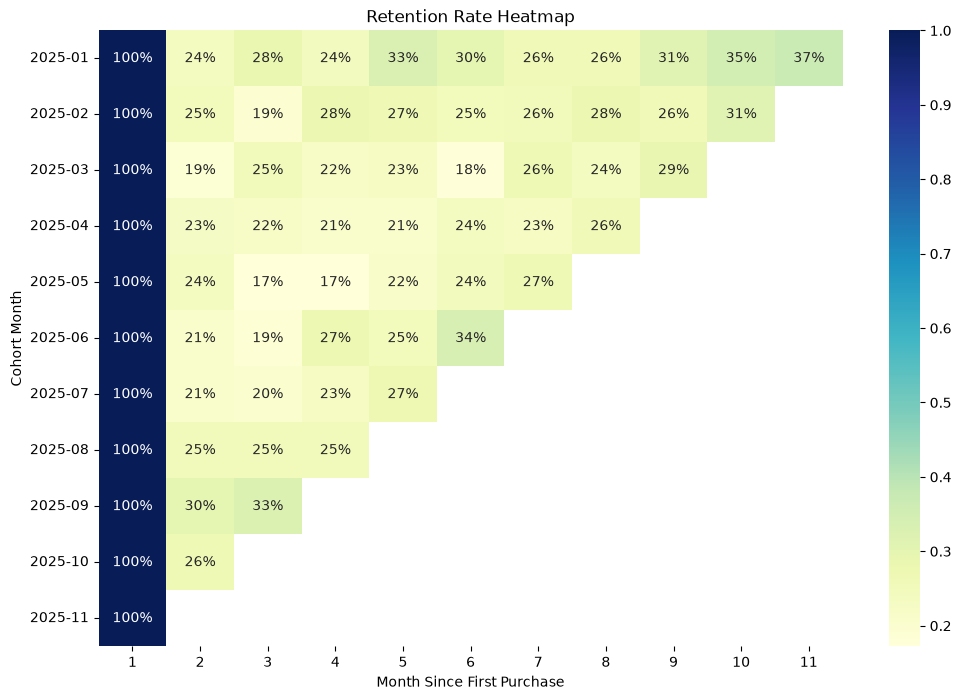

In [13]:
plt.figure(figsize=(12, 8))
sns.heatmap(retention, annot=True, fmt='.0%', cmap='YlGnBu')
plt.title('Retention Rate Heatmap')
plt.xlabel('Month Since First Purchase')
plt.ylabel('Cohort Month')
plt.savefig('Retention_heatmap.png')
plt.show()

In [14]:
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

In [15]:
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'InvoiceNo': pd.Series.nunique,
    'Revenue': 'sum'
}).reset_index()

In [16]:
rfm.columns = ['CustomerID', 'recency_days', 'frequency', 'monetary']

In [17]:
X = rfm[['recency_days', 'frequency', 'monetary']].copy()

# frequency and monetary are very skewed (a few customers spend millions),
# so take the log first; otherwise those few customers dominate K-Means
X['frequency'] = np.log1p(X['frequency'])
X['monetary'] = np.log1p(X['monetary'])
X

,recency_days,frequency,monetary
0,326,1.098612,8.583617
1,2,2.079442,12.975027
2,75,1.609438,11.319092
3,19,0.693147,12.078672
4,310,0.693147,10.782582
...,...,...,...
4367,278,0.693147,9.847359
4368,181,0.693147,10.166237
4369,8,1.386294,10.491600
4370,4,2.833213,14.513023


In [18]:
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()
X_scaled = ss.fit_transform(X)
X_scaled

array([[ 2.32202285, -0.46749327, -2.05264488],
       [-0.89373323,  0.86440534,  1.04019825],
       [-0.1691956 ,  0.22617276, -0.12606725],
       ...,
       [-0.83418219, -0.07684082, -0.70886427],
       [-0.87388289,  1.88797556,  2.12339875],
       [-0.48680114, -0.07684082,  0.52982513]], shape=(4372, 3))

In [19]:
%pip install yellowbrick

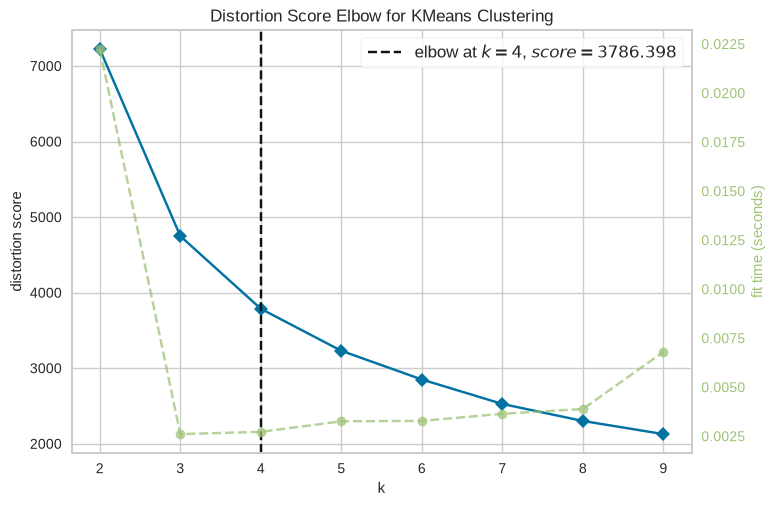

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [20]:
from sklearn.cluster import KMeans
from yellowbrick.cluster import KElbowVisualizer 

model = KMeans(random_state=30)
v = KElbowVisualizer(model, k=(2, 10))
v.fit(X_scaled)
v.show()

In [21]:
final_model = KMeans(n_clusters=4, random_state=42, n_init=10)
final_model.fit(X_scaled)

,n_clusters,4
,init,'k-means++'
,n_init,10
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [22]:
rfm['Cluster'] = final_model.labels_

In [23]:
cluster_profile = rfm.groupby('Cluster').agg({
    'recency_days': 'median',
    'frequency': 'median',
    'monetary': 'median',
    'CustomerID': 'count'
}).rename(columns={'CustomerID': 'NumCustomers'}).round(1)

# share of customers and share of revenue in each cluster
cluster_profile['% of customers'] = (cluster_profile['NumCustomers'] / cluster_profile['NumCustomers'].sum() * 100).round(1)
cluster_profile['% of revenue'] = (rfm.groupby('Cluster')['monetary'].sum() / rfm['monetary'].sum() * 100).round(1)

In [24]:
cluster_profile

,recency_days,frequency,monetary,NumCustomers,% of customers,% of revenue
Cluster,,,,,,
0,54.0,1.0,46807.6,1278,29.2,6.7
1,260.5,1.0,41064.8,918,21.0,5.1
2,30.0,4.0,193252.6,1515,34.7,34.0
3,10.0,13.0,586465.7,661,15.1,54.3


In [25]:
# name each cluster from its own numbers, so the names are right whatever number K-Means gives it
by_freq = cluster_profile.sort_values(['frequency', 'recency_days'], ascending=[False, True]).index
champions = by_freq[0]          # buys most often
loyal = by_freq[1]              # second most often
one_timers = cluster_profile.loc[by_freq[2:]].sort_values('recency_days').index
new_one_time = one_timers[0]    # bought once, recently
lost_one_time = one_timers[1]   # bought once, long ago

cluster_names = {champions: 'Champions', loyal: 'Loyal Repeaters',
                 new_one_time: 'New One-Time Buyers', lost_one_time: 'Lost One-Time Buyers'}
cluster_profile['Segment'] = cluster_profile.index.map(cluster_names)
cluster_profile

,recency_days,frequency,monetary,NumCustomers,% of customers,% of revenue,Segment
Cluster,,,,,,,
0,54.0,1.0,46807.6,1278,29.2,6.7,New One-Time Buyers
1,260.5,1.0,41064.8,918,21.0,5.1,Lost One-Time Buyers
2,30.0,4.0,193252.6,1515,34.7,34.0,Loyal Repeaters
3,10.0,13.0,586465.7,661,15.1,54.3,Champions


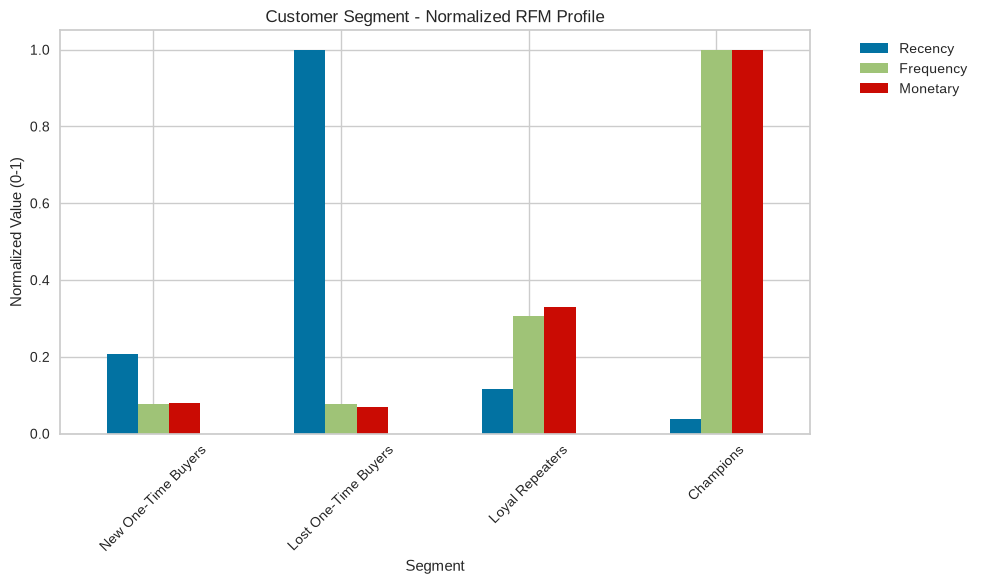

In [26]:
df_plot = cluster_profile.copy()
cols = ['recency_days', 'frequency', 'monetary']
df_plot[cols] = df_plot[cols].apply(lambda x: x / x.max())

df_plot.set_index('Segment')[cols].plot(kind='bar', figsize=(10, 6))
plt.title('Customer Segment - Normalized RFM Profile')
plt.ylabel('Normalized Value (0-1)')
plt.xticks(rotation=45)
plt.legend(['Recency', 'Frequency', 'Monetary'], bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('rfm_profile.png')
plt.show()